# 3 · Cropping

`get_cropped` cuts the cube down along any of three axes at once — space, production time
and leadtime — and returns a **new** `MeteoRaster`. All bounds are **inclusive**, and
every argument is optional, so you crop only the axes you name.

**Needs:** core dependencies, plus `matplotlib` for the closing figures.

In [1]:
import importlib.util
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Environment noise, nothing to do with meteoraster: xarray probes every NetCDF/GRIB
# backend it can find (cfgrib needs the ecCodes binary), and this conda env's h5py and
# HDF5 builds differ by a patch release.
warnings.filterwarnings('ignore', message='(?s).*ecCodes.*')
warnings.filterwarnings('ignore', message='(?s).*h5py is running against HDF5.*')

# Report warnings without their absolute path, so the committed output does not carry
# one machine's directory layout. The warnings themselves stay visible.
def brief_warning(message, category, filename, lineno, line=None):
    return '%s:%d: %s: %s\n' % (Path(filename).name, lineno, category.__name__, message)


warnings.formatwarning = brief_warning

# Run straight from a clone: if `meteoraster` is not installed in this environment,
# fall back to the repository root one level up.
if importlib.util.find_spec('meteoraster') is None:
    sys.path.insert(0, str(Path('..').resolve()))

from meteoraster import MeteoRaster

RESOURCES = Path('..') / 'tests' / 'resources'

plt.rcParams['figure.dpi'] = 100
pd.set_option('display.width', 110)

forecast = MeteoRaster.load(RESOURCES / 'tethys_NOAA_GFS_0.25_2026.02.02.nct', verbose=False)


def summarise(mr, label):
    """Shape and extent of a raster, as one row."""
    leads = pd.to_timedelta(mr.leadtimes)
    prods = pd.to_datetime(mr.production_datetime)
    return pd.Series({
        'shape': str(mr.data.shape),
        'productions': '%s .. %s' % (prods[0].date(), prods[-1].date()),
        'leadtimes': '%s .. %s' % (leads[0], leads[-1]),
        'lat': '%.2f .. %.2f N' % (mr.latitudes.min(), mr.latitudes.max()),
        'lon': '%.2f .. %.2f E' % (mr.longitudes.min(), mr.longitudes.max()),
        'MB': round(mr.data.nbytes / 1e6, 1),
    }, name=label)


summarise(forecast, 'full file').to_frame().T

,shape,productions,leadtimes,lat,lon,MB
full file,"(7, 1, 129, 29, 57)",2026-02-02 .. 2026-02-08,0 days 00:00:00 .. 16 days 00:00:00,47.00 .. 54.00 N,-2.00 .. 12.00 E,6.0


## Cropping in space

Give a latitude and longitude window. The kept block is the **bounding box of the cells
that fall inside it**, so the result stays a rectangle.

In [2]:
region = forecast.get_cropped(from_lat=49.5, to_lat=52.0, from_lon=3.0, to_lon=8.0)

pd.concat([summarise(forecast, 'full file'), summarise(region, 'region crop')], axis=1).T

,shape,productions,leadtimes,lat,lon,MB
full file,"(7, 1, 129, 29, 57)",2026-02-02 .. 2026-02-08,0 days 00:00:00 .. 16 days 00:00:00,47.00 .. 54.00 N,-2.00 .. 12.00 E,6.0
region crop,"(7, 1, 129, 11, 21)",2026-02-02 .. 2026-02-08,0 days 00:00:00 .. 16 days 00:00:00,49.50 .. 52.00 N,3.00 .. 8.00 E,0.8


On a 0.25° grid a small catchment lands on very few cells. The Vesdre basin used in
notebook 6 spans 5.64–6.26 E and 50.43–50.68 N — its bounding box is **one row by three
columns**:

In [3]:
vesdre = forecast.get_cropped(from_lat=50.4, to_lat=50.7, from_lon=5.6, to_lon=6.3)

print('shape:', vesdre.data.shape)
print('latitudes :', vesdre.latitudes.ravel()[:3])
print('longitudes:', vesdre.longitudes[0])
print('\nThat is the whole reason notebook 6 finds duplicate catchment series.')

shape: (7, 1, 129, 1, 3)
latitudes : [50.5 50.5 50.5]
longitudes: [5.75 6.   6.25]

That is the whole reason notebook 6 finds duplicate catchment series.


## Cropping in production time

`from_prod_date` and `to_prod_date` take anything `numpy.datetime64` accepts — a
`pd.Timestamp`, a `datetime`, or a string.

In [4]:
dates = pd.to_datetime(forecast.production_datetime)
midweek = forecast.get_cropped(from_prod_date=dates[2], to_prod_date=dates[4])

print('all productions :', [str(d.date()) for d in dates])
print('kept            :', [str(d.date()) for d in pd.to_datetime(midweek.production_datetime)])
print('shape           :', midweek.data.shape)

all productions : ['2026-02-02', '2026-02-03', '2026-02-04', '2026-02-05', '2026-02-06', '2026-02-07', '2026-02-08']
kept            : ['2026-02-04', '2026-02-05', '2026-02-06']
shape           : (3, 1, 129, 29, 57)


## Cropping in leadtime

`from_leadtime` / `to_leadtime` take a `pd.Timedelta`. Keeping only the first 24 hours of
a 16-day forecast turns 129 columns into 9:

In [5]:
day_one = forecast.get_cropped(to_leadtime=pd.Timedelta(hours=24))

print('leadtimes kept:', [str(t) for t in pd.to_timedelta(day_one.leadtimes)])
pd.concat([summarise(forecast, 'full file'), summarise(day_one, 'first 24 h')], axis=1).T

leadtimes kept: ['0 days 00:00:00', '0 days 03:00:00', '0 days 06:00:00', '0 days 09:00:00', '0 days 12:00:00', '0 days 15:00:00', '0 days 18:00:00', '0 days 21:00:00', '1 days 00:00:00']


,shape,productions,leadtimes,lat,lon,MB
full file,"(7, 1, 129, 29, 57)",2026-02-02 .. 2026-02-08,0 days 00:00:00 .. 16 days 00:00:00,47.00 .. 54.00 N,-2.00 .. 12.00 E,6.0
first 24 h,"(7, 1, 9, 29, 57)",2026-02-02 .. 2026-02-08,0 days 00:00:00 .. 1 days 00:00:00,47.00 .. 54.00 N,-2.00 .. 12.00 E,0.4


> ⚠ `from_leadtime=pd.Timedelta(0)` is **falsy**, so it is ignored — leadtime 0 is already
> the start of the forecast anyway, but do not rely on it as a filter.

## All three at once

The arguments compose, and cropping early is what keeps the expensive work later cheap:
the zonal quantiles in notebook 6 run on a cube like this one, not on the full archive.

In [6]:
small = forecast.get_cropped(
    from_lat=49.5, to_lat=52.0,
    from_lon=3.0, to_lon=8.0,
    from_prod_date=dates[2],
    to_leadtime=pd.Timedelta(hours=48),
)

pd.concat([summarise(forecast, 'full file'), summarise(small, 'cropped')], axis=1).T

,shape,productions,leadtimes,lat,lon,MB
full file,"(7, 1, 129, 29, 57)",2026-02-02 .. 2026-02-08,0 days 00:00:00 .. 16 days 00:00:00,47.00 .. 54.00 N,-2.00 .. 12.00 E,6.0
cropped,"(5, 1, 17, 11, 21)",2026-02-04 .. 2026-02-08,0 days 00:00:00 .. 2 days 00:00:00,49.50 .. 52.00 N,3.00 .. 8.00 E,0.1


In [7]:
print('%.1f MB -> %.2f MB   (%.1f%% of the original)'
      % (forecast.data.nbytes / 1e6, small.data.nbytes / 1e6,
         100 * small.data.nbytes / forecast.data.nbytes))

6.0 MB -> 0.08 MB   (1.3% of the original)


## Seeing it

The mean precipitation field over the whole domain, with the region crop drawn on top.
`MeteoRaster` also plots this on a real projection — see notebook 4 — but plain
`pcolormesh` on the stored coordinate grids is enough to show what cropping did.

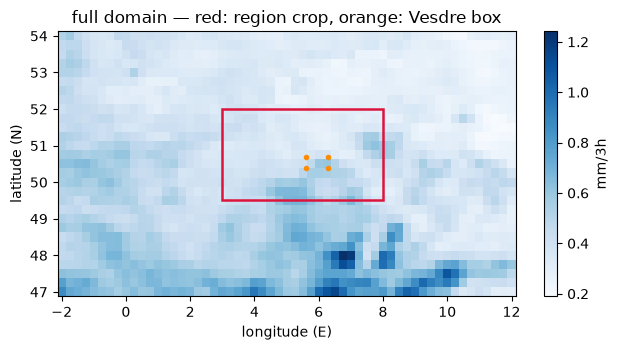

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))

field = np.nanmean(forecast.data, axis=(0, 1, 2))
mesh = ax.pcolormesh(forecast.longitudes, forecast.latitudes, field,
                     cmap='Blues', shading='nearest')
fig.colorbar(mesh, ax=ax, label=forecast.units)

ax.add_patch(plt.Rectangle((3.0, 49.5), 5.0, 2.5, fill=False, color='crimson', lw=1.8))
ax.plot(*np.meshgrid([5.6, 6.3], [50.4, 50.7]), 'o', color='darkorange', ms=3)
ax.set(xlabel='longitude (E)', ylabel='latitude (N)',
       title='full domain — red: region crop, orange: Vesdre box')
fig.tight_layout()

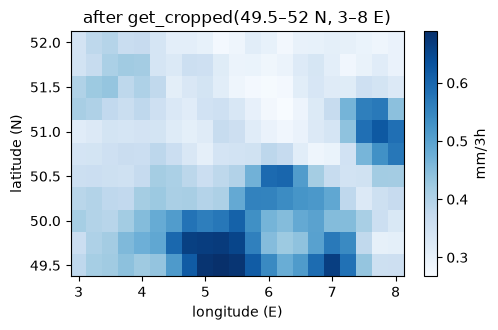

In [9]:
fig, ax = plt.subplots(figsize=(5.2, 3.4))

mesh = ax.pcolormesh(region.longitudes, region.latitudes,
                     np.nanmean(region.data, axis=(0, 1, 2)), cmap='Blues', shading='nearest')
fig.colorbar(mesh, ax=ax, label=region.units)
ax.set(xlabel='longitude (E)', ylabel='latitude (N)',
       title='after get_cropped(49.5–52 N, 3–8 E)')
fig.tight_layout()

## Related

- `trim()` drops leading and trailing **all-NaN** productions. It mutates in place and
  returns `None`. Useful straight after a `join`.
- `load(file, productions=…, leadtimes=…)` crops *while reading*, so the full cube never
  has to exist — see notebook 2.

In [10]:
trimmed = forecast.copy()
before = trimmed.data.shape
trimmed.trim()
print('trim(): %s -> %s   (the missing production is in the middle here, so nothing is dropped)'
      % (before, trimmed.data.shape))

trim(): (7, 1, 129, 29, 57) -> (7, 1, 129, 29, 57)   (the missing production is in the middle here, so nothing is dropped)


---
**Next:** [04 · Plotting](04_plotting.ipynb).